# Tourism Demand Gap → U.S. Foodservice Employment
**Executed retrospective macro lead-indicator falsification · 2026-10-26**

This study tests the U.S. **food services and drinking places (NAICS 722)** target, not the accommodation target in the prior study. The three underlying series are **deliberately reused** from the previously frozen BTS/BLS panel; this is not independent dataset replication. Historical release vintages are unavailable, so this is **not point-in-time equity alpha**. The 15 sections mirror `STUDY_TEMPLATE.md`.

## 01. Abstract
**Question:** Can a lagged passenger-mile-versus-lodging employment gap improve three-month-ahead forecasts of restaurant/foodservice payroll growth? We explicitly allow a null result. Industry payroll growth is not corporate fundamentals or shareholder returns. The notebook recomputes the formation panel and OOS forecasts from frozen inputs and inspects 1,000 block-shuffle refits, 2,000 paired block-bootstrap draws and 1,000 exposure perturbations produced by the documented deterministic analysis entrypoint.

In [1]:
from pathlib import Path
import json, hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
import io
import run_analysis as ra
ROOT=Path.cwd(); raw=ra.load_raw(); panel=ra.build_panel(raw); oos=ra.walkforward(panel)
metrics=json.loads((ROOT/'results/metrics.json').read_text())
print('Raw rows:',len(raw),'Panel rows:',len(panel),'Purged OOS origins:',len(oos))
print('Source SHA256:',hashlib.sha256(ra.RAW.read_bytes()).hexdigest())
assert metrics['raw_sha256']==hashlib.sha256(ra.RAW.read_bytes()).hexdigest()

Raw rows: 153 Panel rows: 134 Purged OOS origins: 70
Source SHA256: 98ad34cabef652c021869fcfa74515a322272ddfb53c3e84dcfa65a5d9af5cc0


## 02. Research Design & Hypotheses
**H1:** Travel growth transmits into restaurant labor demand. **H2:** The fixed tourism gap improves 3-month OOS RMSE against the historical mean, persistence and multivariate controls. **H3:** Improvement survives release buffers, regime exclusions, block-aware shuffles, exposure uncertainty and alternative horizons.

**Counterthesis:** local dining dominates air travel, airline and hotel signals are measured at different stages of the cycle, and the pandemic creates nonstationary labor-market responses. **Failure rule:** do not claim alpha when the full model fails simple baselines or robustness.

In [2]:
print('Design: target = FOOD YoY at t+3; BTS air availability t-4; BLS inputs t-2; label embargo h+2.')
print('Evaluation start:',oos.date.min().date(),'end:',oos.date.max().date())
print('First training origin cutoff:',oos.iloc[0].last_train_origin,'first training size:',oos.iloc[0].n_train)

Design: target = FOOD YoY at t+3; BTS air availability t-4; BLS inputs t-2; label embargo h+2.
Evaluation start: 2019-09-01 end: 2025-06-01
First training origin cutoff: 2019-04-01 first training size: 48


## 03. Industry Context
BLS **CES7072200001** covers food services and drinking places, a different NAICS target from accommodation **CES7072100001**. BTS **AIRRPMTSID11** covers U.S. air carrier revenue passenger miles. Travel demand may affect tourist-oriented restaurants but not necessarily neighborhood quick-service establishments. **No segment revenue shares or restaurant issuer exposure weights are inferred.** Official September 2026 foodservice payroll is 12,393.0 thousand; accommodation payroll is 1,916.5 thousand (BLS release 2026-10-02).

In [3]:
display(raw[[ra.FOOD,ra.HOTEL,ra.AIR]].tail(7).rename(columns={ra.FOOD:'Foodservice employees (000s)',ra.HOTEL:'Accommodation employees (000s)',ra.AIR:'Air RPM (000s)'}))
print('Data range:',raw.index.min().date(),raw.index.max().date())

,Foodservice employees (000s),Accommodation employees (000s),Air RPM (000s)
date,,,
2026-03-01,12355.2,1936.4,96526471.0
2026-04-01,12360.1,1924.1,95242878.0
2026-05-01,12385.0,1938.2,95217510.0
2026-06-01,12378.0,1916.1,94921559.0
2026-07-01,12348.4,1913.4,NaN
2026-08-01,12382.2,1920.1,NaN
2026-09-01,12393.0,1916.5,NaN


Data range: 2014-01-01 2026-09-01


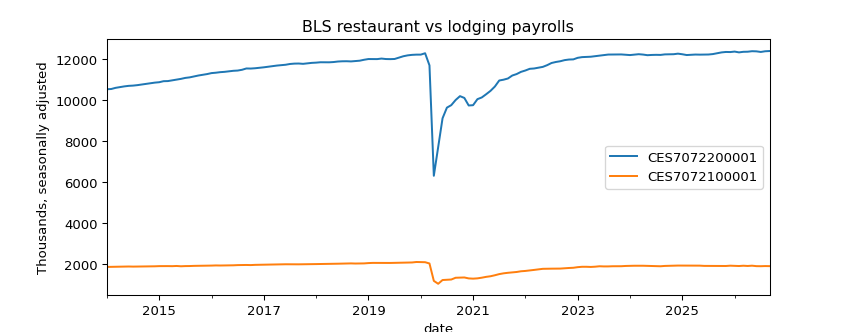

In [4]:
fig,ax=plt.subplots(figsize=(9,3.5));raw[[ra.FOOD,ra.HOTEL]].plot(ax=ax);ax.set(title='BLS restaurant vs lodging payrolls',ylabel='Thousands, seasonally adjusted');buf=io.BytesIO();fig.savefig(buf,format="png",dpi=95);display(Image(data=buf.getvalue()));plt.close(fig)

## 04. Data & Source Integrity
**A sources:** BTS and BLS via FRED official series pages. **B:** inherited frozen manually transcribed panel and its prior QA. **C:** secondary press context excluded from estimation. Exact URLs, units, observation windows, update dates, revision policies, and historical-vintage status are in `data/source_register.csv`. The raw panel is fixed at 153 monthly calendar rows; BTS ends June 2026 and is not forward-filled. The prior file's manual transcription is spot-checked against official latest observations but not audited row-by-row.

In [5]:
source=pd.read_csv(ROOT/'data/source_register.csv');display(source[['source_id','grade','instrument','reported_update_2026','historical_vintages','usage']]);print('Missing by series:');display(raw.isna().sum().to_frame('missing_months'))

,source_id,grade,instrument,reported_update_2026,historical_vintages,usage
0,A1,A,AIRRPMTSID11,2026-10-01 09:01 CDT,NO,lagged air demand signal
1,A2,A,CES7072100001,2026-10-02 08:26 CDT,NO,accommodation control and signal component
2,A3,A,CES7072200001,2026-10-02 08:26 CDT,NO,foodservice target and persistence baseline
3,B1,B,2026-10-26 frozen CSV,2026-10-26 archive date,NO,"reused frozen source bytes, not independent ne..."
4,C1,C,restaurant employment news,2026-10-05,NaN,"context only, excluded from model"


Missing by series:


,missing_months
AIRRPMTSID11,3
CES7072100001,0
CES7072200001,0


In [6]:
spot=pd.DataFrame({'expected':[12393.0,1916.5,94921559.0], 'observed':[raw.loc['2026-09-01',ra.FOOD],raw.loc['2026-09-01',ra.HOTEL],raw.loc['2026-06-01',ra.AIR]]},index=['BLS foodservice Sep 2026','BLS accommodation Sep 2026','BTS air Jun 2026']);spot['match']=np.isclose(spot.expected,spot.observed);display(spot);assert spot['match'].all()

,expected,observed,match
BLS foodservice Sep 2026,12393.0,12393.0,True
BLS accommodation Sep 2026,1916.5,1916.5,True
BTS air Jun 2026,94921559.0,94921559.0,True


## 05. Point-in-Time Availability
For forecast origin month \(t\), use BTS values at most \(t-4\) and BLS values at most \(t-2\). Train only on historical origins \(s\le t-h-2\), where \(h=3\), so labels are assumed released by the current formation date. **This does not reconstruct true historical vintages**: benchmark revisions and seasonality are still future information in the 2026 snapshot. Exact publication dates for every historical row are **UNKNOWN**.

In [7]:
audit=oos[['date','last_train_origin','n_train']].copy();audit['embargo_months']=audit.apply(lambda x: (x.date.year-pd.Timestamp(x.last_train_origin).year)*12+x.date.month-pd.Timestamp(x.last_train_origin).month,axis=1);display(audit.head(8));assert audit.embargo_months.min()>=5

,date,last_train_origin,n_train,embargo_months
0,2019-09-01,2019-04-01,48,5
1,2019-10-01,2019-05-01,49,5
2,2019-11-01,2019-06-01,50,5
3,2019-12-01,2019-07-01,51,5
4,2020-01-01,2019-08-01,52,5
5,2020-02-01,2019-09-01,53,5
6,2020-03-01,2019-10-01,54,5
7,2020-04-01,2019-11-01,55,5


## 06. Factor Construction
Define \(g_{X,t}^{12}=100(X_t/X_{t-12}-1)\) and fixed nonlinear scaling \(z(x)=\tanh(x/20)\). Then \(F_t=z(g_{AIR,t-4}^{12})-z(g_{HOTEL,t-2}^{12})\), \(y_t=g_{FOOD,t+3}^{12}\), and controls \(C_t=[g_{FOOD,t-2}^{12},g_{FOOD,t-2}^{3},g_{HOTEL,t-2}^{12}]\). A fixed Ridge λ=10 is fitted separately at each origin with train-only centering/scaling. There is no global z-scoring, cross-validation over the OOS period or tuned factor weight.

In [8]:
display(panel[['air_yoy_lag','hotel_yoy_lag','food_yoy_lag','tourism_gap','target']].describe().round(3));assert np.allclose(panel.tourism_gap,panel.air_signal-panel.hotel_signal)

,air_yoy_lag,hotel_yoy_lag,food_yoy_lag,tourism_gap,target
count,134.000,134.000,134.000,134.000,134.000
mean,40.388,1.410,1.800,0.115,1.724
std,201.584,14.664,10.655,0.228,10.652
min,-96.702,-48.924,-47.470,-1.660,-47.470
25%,2.498,0.880,0.878,0.061,0.876
50%,4.228,1.801,2.080,0.124,1.913
75%,7.317,3.422,3.753,0.201,3.753
max,1531.250,34.715,62.858,1.107,62.858


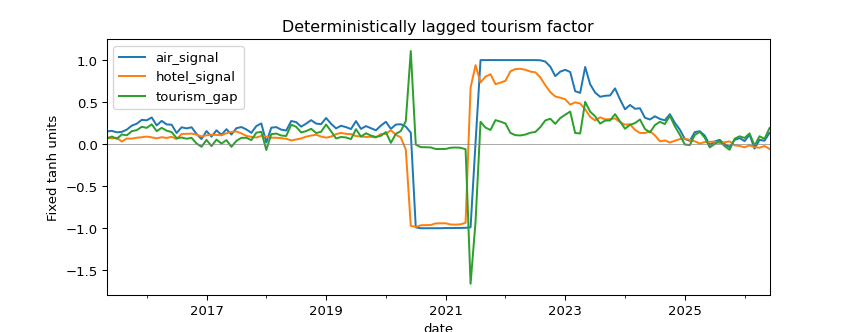

In [9]:
fig,ax=plt.subplots(figsize=(9,3.5));panel[['air_signal','hotel_signal','tourism_gap']].plot(ax=ax);ax.axhline(0,color='grey',lw=.5);ax.set(title='Deterministically lagged tourism factor',ylabel='Fixed tanh units');buf=io.BytesIO();fig.savefig(buf,format="png",dpi=95);display(Image(data=buf.getvalue()));plt.close(fig)

## 07. Exposure & Transmission
The proxy exposure map uses +1 air-travel growth and −1 lodging growth, **not historical firm revenue shares**. These two signals may move with travel demand at different delays, so subtraction is a testable analyst hypothesis rather than an identified structural coefficient. Full-service vs limited-service restaurant exposure, issuer membership, and historical revenue weights are **UNKNOWN**. A leave-one-company-out test is impossible; a leave-one-year-out OOS sensitivity is used and clearly labeled.

In [10]:
display(pd.read_csv(ROOT/'data/exposure_map.csv'));print('Air and hotel factor components correlation:',round(panel.air_signal.corr(panel.hotel_signal),3))

,sector,NAICS,role,model_weight,evidence,effective_as_of,company_specific_weights
0,Food services and drinking places,722,outcome,0.0,BLS CES7072200001; 2026-10-02,2026-10-26,UNKNOWN
1,Accommodation,721,tourism proxy,-1.0,BLS CES7072100001; 2026-10-02,2026-10-26,UNKNOWN
2,Air transport,481,tourism proxy,1.0,BTS AIRRPMTSID11; 2026-10-01,2026-10-26,UNKNOWN


Air and hotel factor components correlation: 0.883


## 08. Outcomes & Baselines
**Endpoint:** next-quarter-month foodservice year-over-year payroll growth, in percentage points. **Baselines on identical origins:** expanding historical mean, foodservice persistence, foodservice momentum+lodging controls, and factor-only. **Challenger:** controls plus tourism gap. Predictions are generated by a purged expanding-window design with at least 48 training observations. Because no firm revenue, EPS, adjusted prices or total returns are included, long-short equity spread, benchmark-adjusted returns, equity IC and net transaction-cost alpha are **not measured**.

In [11]:
sc=pd.DataFrame([{'model':k,**v} for k,v in ra.score(oos).items()]);display(sc.round(3));assert len(oos)==metrics['oos_n'];assert np.isclose(sc.set_index('model').loc['full','rmse'],metrics['scores']['full']['rmse'])

,model,rmse,mae,n
0,mean,15.186,9.368,70
1,persistence,15.619,8.714,70
2,controls,66.047,23.879,70
3,full,71.659,25.185,70
4,factor_only,15.089,9.381,70


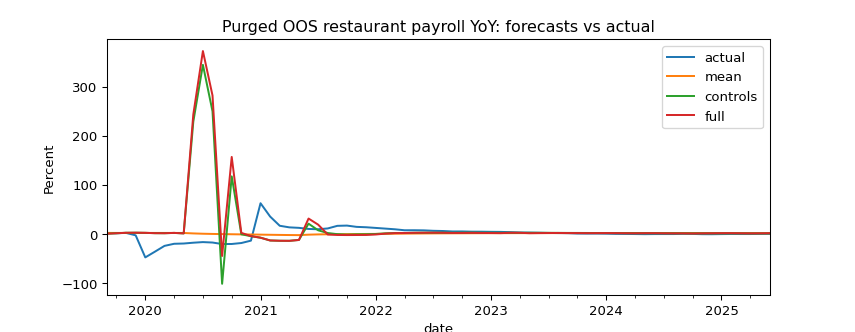

In [12]:
fig,ax=plt.subplots(figsize=(9,3.5));oos.set_index('date')[['actual','mean','controls','full']].plot(ax=ax);ax.set(title='Purged OOS restaurant payroll YoY: forecasts vs actual',ylabel='Percent');buf=io.BytesIO();fig.savefig(buf,format="png",dpi=95);display(Image(data=buf.getvalue()));plt.close(fig)

## 09. Empirical Findings
The full model **does not** beat the control model or the historical mean. Large pandemic-related extrapolation errors make linear multivariate Ridge especially poor. A factor-only model that happens to slightly outperform the historical mean is **not** evidence of incremental value, let alone stock-market alpha. Interpret all errors in percentage points, not percent improvement.

In [13]:
delta=ra.gap(oos);print(f'Primary OOS improvement: controls minus full RMSE = {delta:.3f} percentage points');print('Best RMSE model:',sc.sort_values('rmse').iloc[0]['model']);display(oos[['date','actual','controls','full']].head(8))

Primary OOS improvement: controls minus full RMSE = -5.611 percentage points
Best RMSE model: factor_only


,date,actual,controls,full
0,2019-09-01,2.087215,0.717005,0.722667
1,2019-10-01,1.796233,1.743970,1.736063
2,2019-11-01,2.380119,2.640337,2.622376
3,2019-12-01,-2.544915,2.804682,2.813592
4,2020-01-01,-47.470086,2.520781,2.556190
5,2020-02-01,-35.836812,1.880622,1.876697
6,2020-03-01,-24.011168,1.759855,1.781142
7,2020-04-01,-19.735132,2.393525,2.416165


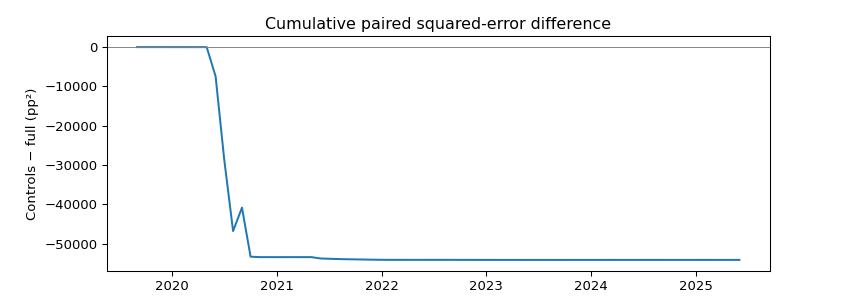

In [14]:
a=oos.actual.to_numpy();paired=(oos.controls.to_numpy()-a)**2-(oos.full.to_numpy()-a)**2;fig,ax=plt.subplots(figsize=(9,3.2));ax.plot(oos.date,np.cumsum(paired));ax.axhline(0,color='grey',lw=.7);ax.set(title='Cumulative paired squared-error difference',ylabel='Controls − full (pp²)');buf=io.BytesIO();fig.savefig(buf,format="png",dpi=95);display(Image(data=buf.getvalue()));plt.close(fig)

## 10. Robustness & Placebos
The entrypoint performs **1,000 12-month block-shuffle full-model refits** (exploratory null), **2,000 paired 12-month circular moving-block bootstrap draws** on OOS errors, and **1,000 independent ±30% exposure-weight perturbation refits**. Block permutation retains within-year dependence but does not satisfy exact exchangeability under a pandemic regime shift. The bootstrap reflects dependence better than IID draws but has finite-block and small-effective-sample limitations.

In [15]:
placebo=pd.read_csv(ROOT/'results/block_shuffle_1000.csv').iloc[:,0].to_numpy();boot=pd.read_csv(ROOT/'results/bootstrap_2000.csv').iloc[:,0].to_numpy();exposure=pd.read_csv(ROOT/'results/exposure_1000.csv');print('Draws:',len(placebo),len(boot),len(exposure));print('Exploratory block-shuffle upper tail:',round((1+np.sum(placebo>=delta))/(len(placebo)+1),4));print('Paired block-bootstrap 95% interval:',np.quantile(boot,[.025,.975]).round(3));print('Positive exposure fraction:',round((exposure.delta_rmse>0).mean(),4));assert len(placebo)>=1000 and len(boot)>=2000 and len(exposure)>=1000

Draws: 1000 2000 1000
Exploratory block-shuffle upper tail: 0.8961
Paired block-bootstrap 95% interval: [-9.725 -0.115]
Positive exposure fraction: 0.0


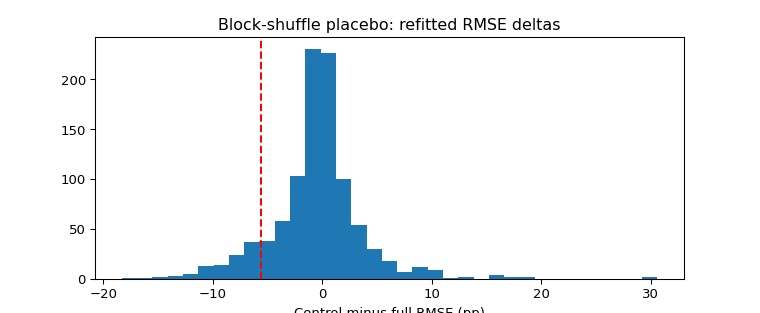

In [16]:
fig,ax=plt.subplots(figsize=(8,3.3));ax.hist(placebo,bins=35);ax.axvline(delta,color='red',ls='--');ax.set(title='Block-shuffle placebo: refitted RMSE deltas',xlabel='Control minus full RMSE (pp)');buf=io.BytesIO();fig.savefig(buf,format="png",dpi=95);display(Image(data=buf.getvalue()));plt.close(fig)

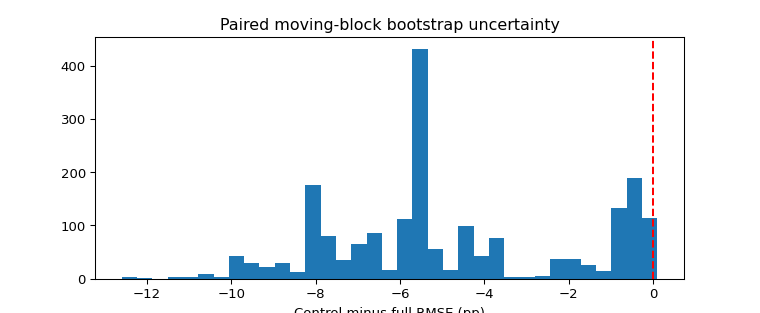

In [17]:
fig,ax=plt.subplots(figsize=(8,3.3));ax.hist(boot,bins=35);ax.axvline(0,color='red',ls='--');ax.set(title='Paired moving-block bootstrap uncertainty',xlabel='Control minus full RMSE (pp)');buf=io.BytesIO();fig.savefig(buf,format="png",dpi=95);display(Image(data=buf.getvalue()));plt.close(fig)

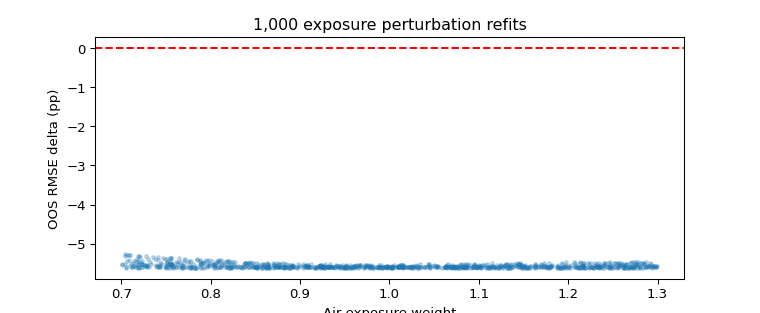

In [18]:
fig,ax=plt.subplots(figsize=(8,3.3));ax.scatter(exposure.air_weight,exposure.delta_rmse,s=7,alpha=.25);ax.axhline(0,color='red',ls='--');ax.set(title='1,000 exposure perturbation refits',xlabel='Air exposure weight',ylabel='OOS RMSE delta (pp)');buf=io.BytesIO();fig.savefig(buf,format="png",dpi=95);display(Image(data=buf.getvalue()));plt.close(fig)

## 11. Regime Sensitivity
The pre-2020 OOS sample is extremely small; it cannot support stable inference. Pandemic 2020–2022 errors dominate full-sample results. Excluding 2020, and using post-2022 origins, checks whether failure is purely one shock. Alternate 1- and 6-month horizons and 5-/6-month BTS buffers alter available origins, so cross-horizon deltas are diagnostic, not apples-to-apples treatment effects.

In [19]:
display(pd.DataFrame([{'regime':k,'n':v['n'],'delta_rmse':v['delta_rmse']} for k,v in metrics['regimes'].items()]).round(3));display(pd.DataFrame([{'experiment':k,'n':v['n'],'delta_rmse':v['delta_controls_minus_full']} for k,v in metrics['robustness'].items()]).round(3))

,regime,n,delta_rmse
0,pre_2020,4,-0.003
1,pandemic_2020_2022,36,-7.825
2,post_2022,30,-0.060
3,excluding_2020,58,-0.428


,experiment,n,delta_rmse
0,horizon_1m,72,1.513
1,horizon_6m,67,-1.942
2,air_release_lag_5m,69,-4.381
3,air_release_lag_6m,68,0.042
4,bls_release_lag_3m,70,-1.001


In [20]:
loo=pd.read_csv(ROOT/'results/leave_one_year_out.csv');display(loo.round(3));print('2020 deletion is OOS score deletion only, not model refitting or issuer exclusion.')

,excluded_year,n,delta_rmse
0,2019,66,-5.779
1,2020,58,-0.428
2,2021,58,-6.196
3,2022,58,-6.163
4,2023,58,-6.164
5,2024,58,-6.165
6,2025,64,-5.868


2020 deletion is OOS score deletion only, not model refitting or issuer exclusion.


## 12. Bias Audit & Verdict
**Historical revision lookahead:** unresolved, so not PIT. **Publication lag:** four-/two-month buffers are assumptions. **Selection/multiple testing:** the factor and horizons were chosen by an analyst; diagnostic variants do not constitute preregistration. **Survivorship:** sector aggregates hide firm closures. **Pandemic/nonstationarity:** extreme structural break drives errors. **Overlapping outcomes:** 70 monthly origins are not 70 independent 3-month-ahead YoY targets. **Transaction costs/shorting/capacity:** untested because no securities. **Verdict:** failed incremental foodservice employment predictor; no fundamentals or equity alpha established.

In [21]:
print('Primary verdict:', 'FAIL' if (delta<=0 or sc.set_index('model').loc['full','rmse']>=sc.set_index('model').loc['mean','rmse']) else 'needs further testing')
print('Historical publication vintages verified?',metrics.get('historical_point_in_time_verified',False))
print('Firm fundamentals tested?',metrics['fundamentals_tested'],'Equity returns tested?',metrics['equity_returns_tested'])

Primary verdict: FAIL
Historical publication vintages verified? False
Firm fundamentals tested? False Equity returns tested? False


## 13. Reproduction
From this study directory: install `requirements.txt`; run `OPENBLAS_NUM_THREADS=1 python run_analysis.py`, `OPENBLAS_NUM_THREADS=1 python -m pytest -q tests`, and run all cells in `research.ipynb` using Jupyter/nbclient. The analysis seed is 20261026; source file hash and OOS RMSE must match committed artifacts. The repository-level `python scripts/validate_studies.py` checks layout, not the scientific validity of a factor.

In [22]:
import platform
print('Python:',platform.python_version(),'numpy:',np.__version__,'pandas:',pd.__version__)
print('Frozen raw SHA256:',hashlib.sha256(ra.RAW.read_bytes()).hexdigest())
print('Figures present:',len(list((ROOT/'figures').glob('*.png'))))
print('Result CSVs:',len(list((ROOT/'results').glob('*.csv'))))

Python: 3.13.5 numpy: 2.3.5 pandas: 2.2.3
Frozen raw SHA256: 98ad34cabef652c021869fcfa74515a322272ddfb53c3e84dcfa65a5d9af5cc0
Figures present: 9
Result CSVs: 7


## 14. Next-Stage Protocol
Obtain official full-history bulk BTS/BLS CSVs and independently compare **every row** against the inherited transcription. Reconstruct true release-vintage series, model publication timestamps and annual benchmark revisions. Add restaurant sales receipts, credit-card spending and regional travel exposure; test real issuer fundamentals before collecting dividend-adjusted returns and evaluating a cost-aware equity portfolio. The negative pilot does not justify optimizing a trading strategy on this snapshot.

In [23]:
checks={'no_missing_target':bool(panel.target.notna().all()),'raw_calendar_complete':bool(raw.index.equals(pd.date_range(raw.index.min(),raw.index.max(),freq='MS'))),'minimum_oos_n':len(oos)>=50,'all_oos_models_same_n':all(x['n']==len(oos) for x in ra.score(oos).values()),'no_lookahead_training_origin':bool(all(pd.Timestamp(v.last_train_origin)<=v.date-pd.DateOffset(months=5) for _,v in oos.iterrows()))};display(pd.Series(checks,name='QA pass'));assert all(checks.values())

no_missing_target               True
raw_calendar_complete           True
minimum_oos_n                   True
all_oos_models_same_n           True
no_lookahead_training_origin    True
Name: QA pass, dtype: bool

## 15. Sources & Artifacts
**Primary:** [BTS AIRRPMTSID11](https://fred.stlouisfed.org/series/AIRRPMTSID11), [BLS CES7072100001](https://fred.stlouisfed.org/series/CES7072100001), [BLS CES7072200001](https://fred.stlouisfed.org/series/CES7072200001); latest source page updates October 1 and 2, 2026. **Frozen derivative:** prior accommodation research's manually transcribed CSV, copied with SHA and QA notes. **Outputs:** source register, frozen and derived panels, OOS scorecard, all refit null draws, paired bootstrap, weight perturbations, 9 diagnostic figures, reproducibility logs and tests. Data vintages remain unknown. All estimates are research-only and are not investment advice.

In [24]:
artifact_counts={'source_register':(ROOT/'data/source_register.csv').exists(),'frozen_data':ra.RAW.exists(),'metrics':(ROOT/'results/metrics.json').exists(),'figures':len(list((ROOT/'figures').glob('*.png'))),'OOS_rows':len(pd.read_csv(ROOT/'results/walk_forward_oos.csv'))};display(pd.Series(artifact_counts,name='Artifact check'));assert artifact_counts['figures']>=3

source_register    True
frozen_data        True
metrics            True
figures               9
OOS_rows             70
Name: Artifact check, dtype: object